# Olist E-Commerce Analysis: Python
**Goal:** go deeper than SQL on three questions:
1. Is the drop in review scores for late deliveries statistically significant?
2. Who are our customers? (RFM segmentation)
3. Do customers come back? (cohort retention)

Then export clean tables for Power BI.

**Data:** the clean views built in `sql/04_cleaning_views.sql` (PostgreSQL database `olist`).

## 0. Setup
Run once in a terminal (with your venv active):
```
pip install pandas numpy matplotlib seaborn scipy sqlalchemy psycopg2-binary python-dotenv jupyter
```

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from dotenv import load_dotenv

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

# Project folders: works whether the notebook runs from the project root or from python/
BASE = Path.cwd().parent if Path.cwd().name == "python" else Path.cwd()
CLEAN_DIR = BASE / "data" / "clean"
IMG_DIR = BASE / "images"
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
IMG_DIR.mkdir(parents=True, exist_ok=True)
print("Project folder:", BASE)

Project folder: c:\Users\rabin\OneDrive\Desktop\Become DA


## 1. Connect to PostgreSQL
The password is read from a `.env` file so it never ends up on GitHub.
Create a file called `.env` in your **project folder** containing one line:
```
PG_PASSWORD=your_postgres_password
```
and add `.env` to your `.gitignore`.

In [6]:
load_dotenv(BASE / ".env")

url = URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password=os.getenv("PG_PASSWORD"),
    host="localhost",
    port=5433,
    database="olist",
)
engine = create_engine(url)

with engine.connect() as conn:
    print(pd.read_sql("SELECT current_database() AS db, COUNT(*) AS orders FROM orders", conn))

      db  orders
0  olist   99441


## 2. Load the clean views

In [7]:
orders = pd.read_sql("SELECT * FROM v_orders_master", engine,
                     parse_dates=["order_purchase_timestamp", "purchase_month",
                                  "order_delivered_customer_date", "order_estimated_delivery_date"])
items = pd.read_sql("SELECT * FROM v_order_items", engine,
                    parse_dates=["order_purchase_timestamp", "purchase_month"])

print("orders:", orders.shape, "| items:", items.shape)
orders.head()

orders: (99441, 19) | items: (112650, 12)


,order_id,order_status,customer_unique_id,customer_city,customer_state,order_purchase_timestamp,purchase_month,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delay_days,is_late,item_count,product_revenue,freight_total,payment_total,main_payment_type,max_installments,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,delivered,871766c5855e863f6eccc05f988b23cb,campos dos goytacazes,RJ,2017-09-13 08:59:02,2017-09-01,2017-09-20 23:43:48,2017-09-29,7.00,-9.00,0.00,1,58.90,13.29,72.19,credit_card,2.00,5.00
1,00048cc3ae777c65dbb7d2a0634bc1ea,delivered,85c835d128beae5b4ce8602c491bf385,uberaba,MG,2017-05-15 21:42:34,2017-05-01,2017-05-22 13:44:35,2017-06-06,7.00,-15.00,0.00,1,21.90,12.69,34.59,boleto,1.00,4.00
2,00054e8431b9d7675808bcb819fb4a32,delivered,635d9ac1680f03288e72ada3a1035803,guararapes,SP,2017-12-10 11:53:48,2017-12-01,2017-12-18 22:03:38,2018-01-04,8.00,-17.00,0.00,1,19.90,11.85,31.75,credit_card,1.00,4.00
3,000576fe39319847cbb9d288c5617fa6,delivered,fda4476abb6307ab3c415b7e6d026526,praia grande,SP,2018-07-04 12:08:27,2018-07-01,2018-07-09 14:04:07,2018-07-25,5.00,-16.00,0.00,1,810.00,70.75,880.75,credit_card,10.00,5.00
4,0005f50442cb953dcd1d21e1fb923495,delivered,0782c41380992a5a533489063df0eef6,jandira,SP,2018-07-02 13:59:39,2018-07-01,2018-07-04 17:28:31,2018-07-23,2.00,-19.00,0.00,1,53.99,11.40,65.39,credit_card,1.00,4.00


## 3. Quick checks

In [8]:
# One row per order? (should print True)
print("order_id unique:", orders["order_id"].is_unique)

# Missing values per column (only columns that have any)
missing = orders.isna().sum()
print(missing[missing > 0].sort_values(ascending=False))

# Order status mix
orders["order_status"].value_counts(normalize=True).mul(100).round(2)

order_id unique: True
order_delivered_customer_date    2965
delivery_days                    2965
delay_days                       2965
is_late                          2965
review_score                      768
payment_total                       1
main_payment_type                   1
max_installments                    1
dtype: int64


order_status
delivered     97.02
shipped        1.11
canceled       0.63
unavailable    0.61
invoiced       0.32
processing     0.30
created        0.01
approved       0.00
Name: proportion, dtype: float64

In [9]:
# Keep delivered orders for the analysis
delivered = orders[orders["order_status"] == "delivered"].copy()

# Monthly orders: find incomplete months at the start and end
monthly = delivered.groupby("purchase_month").agg(orders=("order_id", "count"),
                                                  revenue=("product_revenue", "sum"))
monthly

,orders,revenue
purchase_month,,
2016-09-01,1,134.97
2016-10-01,265,"40,325.11"
2016-12-01,1,10.90
2017-01-01,750,"111,798.36"
2017-02-01,1653,"234,223.40"
2017-03-01,2546,"359,198.85"
2017-04-01,2303,"340,669.68"
2017-05-01,3546,"489,338.25"
2017-06-01,3135,"421,923.37"


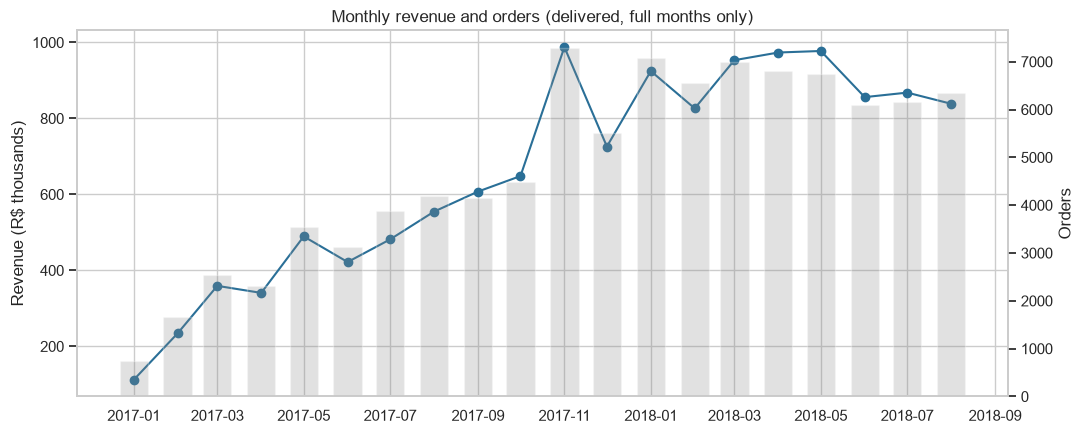

In [10]:
# Full months only: drop months with fewer than 500 delivered orders (the incomplete edges)
full_months = monthly[monthly["orders"] >= 500]

fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.plot(full_months.index, full_months["revenue"] / 1000, marker="o", color="#2a6f97", label="Revenue (R$ thousands)")
ax1.set_ylabel("Revenue (R$ thousands)")
ax2 = ax1.twinx()
ax2.bar(full_months.index, full_months["orders"], width=20, alpha=0.25, color="#888", label="Orders")
ax2.set_ylabel("Orders")
ax2.grid(False)
ax1.set_title("Monthly revenue and orders (delivered, full months only)")
fig.tight_layout()
fig.savefig(IMG_DIR / "monthly_revenue.png", dpi=150)
plt.show()

## 4. Late delivery vs review score: is the difference real?
SQL showed late orders average about 2 stars lower. Here we test whether that could be chance.

Review scores are 1–5 ratings, not truly continuous, so the main test is **Mann-Whitney U**
(no normality assumption). Welch's t-test is shown alongside for comparison.

In [11]:
rev = delivered.dropna(subset=["is_late", "review_score"])
on_time = rev.loc[rev["is_late"] == 0, "review_score"]
late = rev.loc[rev["is_late"] == 1, "review_score"]

summary = rev.groupby("is_late")["review_score"].agg(["count", "mean", "median"])
summary.index = summary.index.map({0: "On time", 1: "Late"})
print(summary, "\n")

u_stat, p_mw = stats.mannwhitneyu(on_time, late, alternative="two-sided")
t_stat, p_t = stats.ttest_ind(on_time, late, equal_var=False)

# Effect size: Cohen's d (how big the difference is, not just whether it exists)
pooled_sd = np.sqrt((on_time.var() + late.var()) / 2)
cohens_d = (on_time.mean() - late.mean()) / pooled_sd

fmt_p = lambda p: "< 1e-300 (effectively 0)" if p == 0 else f"{p:.3g}"
print(f"Mann-Whitney U p-value: {fmt_p(p_mw)}")
print(f"Welch t-test p-value:   {fmt_p(p_t)}")
print("p < 0.05 means the difference is very unlikely to be due to chance.")
print(f"Cohen's d:              {cohens_d:.2f}  (0.2 small, 0.5 medium, 0.8+ large)")

         count  mean  median
is_late                     
On time  89443  4.29    5.00
Late      6381  2.27    1.00 

Mann-Whitney U p-value: < 1e-300 (effectively 0)
Welch t-test p-value:   < 1e-300 (effectively 0)
p < 0.05 means the difference is very unlikely to be due to chance.
Cohen's d:              1.47  (0.2 small, 0.5 medium, 0.8+ large)


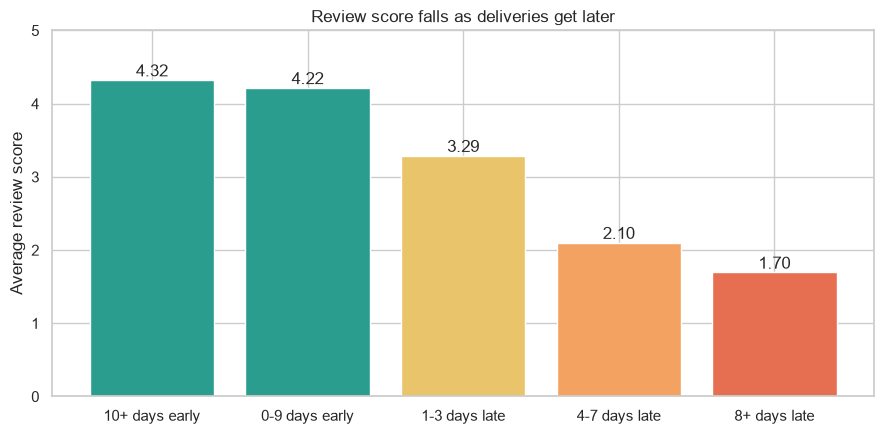

,count,mean
delay_bucket,,
10+ days early,61523,4.32
0-9 days early,27920,4.22
1-3 days late,1852,3.29
4-7 days late,1748,2.10
8+ days late,2781,1.70


In [12]:
bins = [-np.inf, -10, 0, 3, 7, np.inf]
labels = ["10+ days early", "0-9 days early", "1-3 days late", "4-7 days late", "8+ days late"]
rev["delay_bucket"] = pd.cut(rev["delay_days"], bins=bins, labels=labels)

bucket = rev.groupby("delay_bucket", observed=True)["review_score"].agg(["count", "mean"])

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#2a9d8f", "#2a9d8f", "#e9c46a", "#f4a261", "#e76f51"]
ax.bar(bucket.index.astype(str), bucket["mean"], color=colors)
for i, v in enumerate(bucket["mean"]):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center")
ax.set_ylim(0, 5)
ax.set_ylabel("Average review score")
ax.set_title("Review score falls as deliveries get later")
fig.tight_layout()
fig.savefig(IMG_DIR / "review_by_delay.png", dpi=150)
plt.show()
bucket

## 5. RFM customer segmentation
- **Recency:** days since the customer's last order
- **Frequency:** number of orders
- **Monetary:** total spent

Most Olist customers buy only once, so Frequency can't be split into 5 equal groups.
Recency and Monetary use quintile scores (1–5); Frequency uses simple rules (1 order = 1, 2 orders = 3, 3+ = 5).

In [13]:
snapshot = delivered["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm = delivered.groupby("customer_unique_id").agg(
    last_order=("order_purchase_timestamp", "max"),
    frequency=("order_id", "count"),
    monetary=("product_revenue", "sum"),
    customer_state=("customer_state", "first"),
)
rfm["recency_days"] = (snapshot - rfm["last_order"]).dt.days

# rank(method="first") avoids errors when many customers share the same value
rfm["R"] = pd.qcut(rfm["recency_days"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["F"] = np.select([rfm["frequency"] >= 3, rfm["frequency"] == 2], [5, 3], default=1)

def segment(row):
    if row.F >= 3 and row.R >= 4:
        return "Champions"
    if row.F >= 3:
        return "Loyal"
    if row.R >= 4 and row.M >= 4:
        return "Promising (new, high value)"
    if row.R >= 4:
        return "New customers"
    if row.R == 3:
        return "Needs attention"
    if row.M >= 4:
        return "At risk (high value)"
    return "Lost"

rfm["segment"] = rfm.apply(segment, axis=1)
rfm.head()

,last_order,frequency,monetary,customer_state,recency_days,R,M,F,segment
customer_unique_id,,,,,,,,,
0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,1,129.90,SP,112,4,4,1,"Promising (new, high value)"
0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,1,18.90,SP,115,4,1,1,New customers
0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,1,69.00,SC,537,1,2,1,Lost
0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,1,25.99,PA,321,2,1,1,Lost
0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,1,180.00,SP,288,2,5,1,At risk (high value)


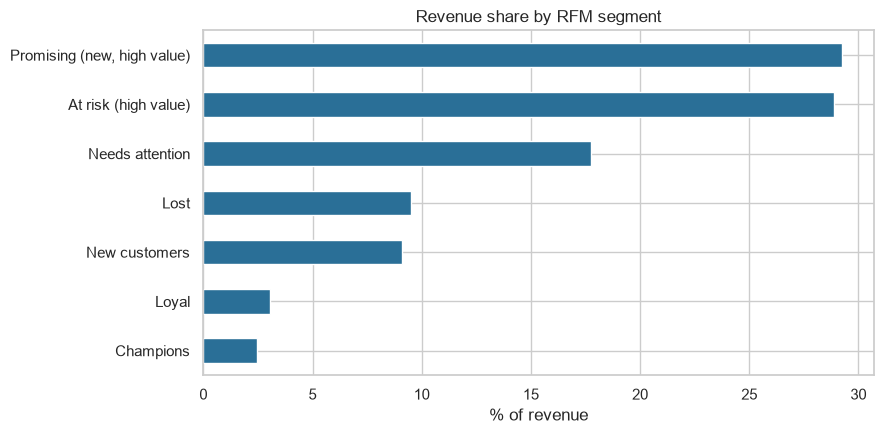

,customers,avg_recency_days,avg_orders,avg_spend,total_revenue,pct_customers,pct_revenue
segment,,,,,,,
"Promising (new, high value)",14478,91.66,1.00,267.12,"3,867,380.98",15.51,29.25
At risk (high value),13788,394.55,1.00,276.77,"3,816,095.18",14.77,28.86
Needs attention,18075,219.93,1.00,129.95,"2,348,933.29",19.36,17.77
Lost,22559,395.16,1.00,55.76,"1,257,985.44",24.16,9.51
New customers,21657,89.57,1.00,55.53,"1,202,694.47",23.20,9.10
Loyal,1593,319.79,2.08,252.55,"402,305.03",1.71,3.04
Champions,1208,89.09,2.15,269.95,"326,103.72",1.29,2.47


In [14]:
seg = rfm.groupby("segment").agg(
    customers=("frequency", "size"),
    avg_recency_days=("recency_days", "mean"),
    avg_orders=("frequency", "mean"),
    avg_spend=("monetary", "mean"),
    total_revenue=("monetary", "sum"),
)
seg["pct_customers"] = 100 * seg["customers"] / seg["customers"].sum()
seg["pct_revenue"] = 100 * seg["total_revenue"] / seg["total_revenue"].sum()
seg = seg.sort_values("total_revenue", ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
seg["pct_revenue"].sort_values().plot.barh(ax=ax, color="#2a6f97")
ax.set_xlabel("% of revenue")
ax.set_ylabel("")
ax.set_title("Revenue share by RFM segment")
fig.tight_layout()
fig.savefig(IMG_DIR / "rfm_segments.png", dpi=150)
plt.show()
seg

## 6. Cohort retention
Group customers by the month of their **first** order, then track what % ordered again
in each following month.

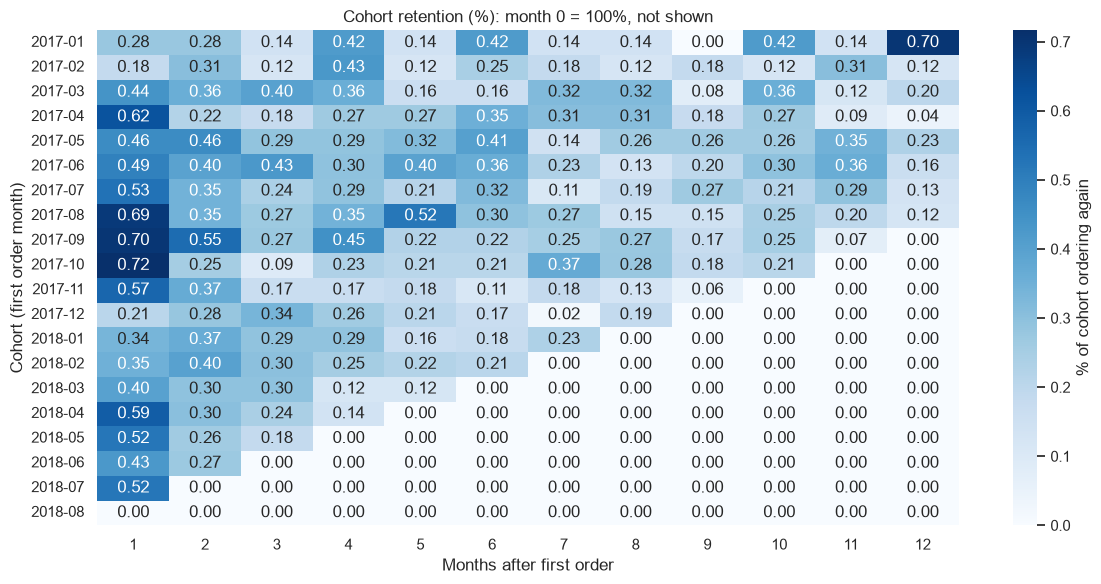

Average month-1 retention: 0.45%


In [15]:
d = delivered[["customer_unique_id", "order_purchase_timestamp"]].copy()
d["order_month"] = d["order_purchase_timestamp"].dt.to_period("M")
d["cohort"] = d.groupby("customer_unique_id")["order_month"].transform("min")
d["months_since"] = (d["order_month"] - d["cohort"]).apply(lambda x: x.n)

cohort_counts = (d.groupby(["cohort", "months_since"])["customer_unique_id"]
                   .nunique().unstack(fill_value=0))
cohort_size = cohort_counts[0]
retention = cohort_counts.div(cohort_size, axis=0)

# Keep cohorts with at least 500 customers and the first 12 months
retention = retention[cohort_size >= 500].iloc[:, :13]

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(retention.iloc[:, 1:] * 100, annot=True, fmt=".2f", cmap="Blues",
            cbar_kws={"label": "% of cohort ordering again"}, ax=ax)
ax.set_xlabel("Months after first order")
ax.set_ylabel("Cohort (first order month)")
ax.set_title("Cohort retention (%): month 0 = 100%, not shown")
fig.tight_layout()
fig.savefig(IMG_DIR / "cohort_retention.png", dpi=150)
plt.show()

print(f"Average month-1 retention: {retention[1].mean():.2%}")

## 7. Export clean tables for Power BI

In [16]:
# Fact table: one row per order
orders.to_csv(CLEAN_DIR / "fact_orders.csv", index=False)

# Fact table: one row per order item (for category / seller analysis)
items.to_csv(CLEAN_DIR / "fact_order_items.csv", index=False)

# Customer dimension with RFM segment
rfm.reset_index().to_csv(CLEAN_DIR / "dim_customers_rfm.csv", index=False)

# Date dimension covering the whole order period
dates = pd.DataFrame({"date": pd.date_range(orders["order_purchase_timestamp"].min().normalize(),
                                            orders["order_purchase_timestamp"].max().normalize())})
dates["year"] = dates["date"].dt.year
dates["month_num"] = dates["date"].dt.month
dates["month_name"] = dates["date"].dt.strftime("%b")
dates["year_month"] = dates["date"].dt.strftime("%Y-%m")
dates["weekday"] = dates["date"].dt.day_name()
dates.to_csv(CLEAN_DIR / "dim_date.csv", index=False)

for f in sorted(CLEAN_DIR.glob("*.csv")):
    print(f.name, f"{f.stat().st_size / 1e6:.1f} MB")

dim_customers_rfm.csv 8.4 MB
dim_date.csv 0.0 MB
fact_order_items.csv 20.0 MB
fact_orders.csv 20.4 MB


## 8. Key findings
*Fill in with your own numbers after running the notebook.*

1. **Late delivery hurts reviews:** late orders average _2.27__ stars vs __4.29_ on time (Mann-Whitney p = ___, Cohen's d = ___).
2. **Customers rarely return:** only ___% of customers ordered more than once; average month-1 retention is ___%.
3. **Revenue concentration:** the ___ segment holds ___% of revenue.
4. **Recommendation:** ___